In [6]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("Titanic-Dataset.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [8]:
#To get the missing values
print(df.isnull().sum())  

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [9]:
#Getting the missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [10]:
#As age contains outliers and mean is affected by outliers
df["Age"] = df["Age"].fillna(df["Age"].median())
print(df["Age"].isnull().sum())

0


In [11]:
#As embarkeed contained categorical values
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print(df["Embarked"].isnull().sum())

0


In [12]:
#As it has very high percentage of missing values
df.drop(columns=["Cabin"], inplace=True)

In [13]:
print("Dataset Shape:", df.shape)
print(df.isnull().sum())

Dataset Shape: (891, 11)
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [14]:
#Encoding
label_encoder = LabelEncoder()
df["Sex"] = label_encoder.fit_transform(df["Sex"])
df[["Sex"]].head()

,Sex
0,1
1,0
2,0
3,0
4,1


In [15]:
onehot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded_data = onehot_encoder.fit_transform(df[["Embarked"]])
encoded_columns = onehot_encoder.get_feature_names_out(["Embarked"])
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=df.index
)
df = pd.concat([df, encoded_df], axis=1)
display(df[["Embarked", "Embarked_C", "Embarked_Q", "Embarked_S"]].head())

,Embarked,Embarked_C,Embarked_Q,Embarked_S
0,S,0.0,0.0,1.0
1,C,1.0,0.0,0.0
2,S,0.0,0.0,1.0
3,S,0.0,0.0,1.0
4,S,0.0,0.0,1.0


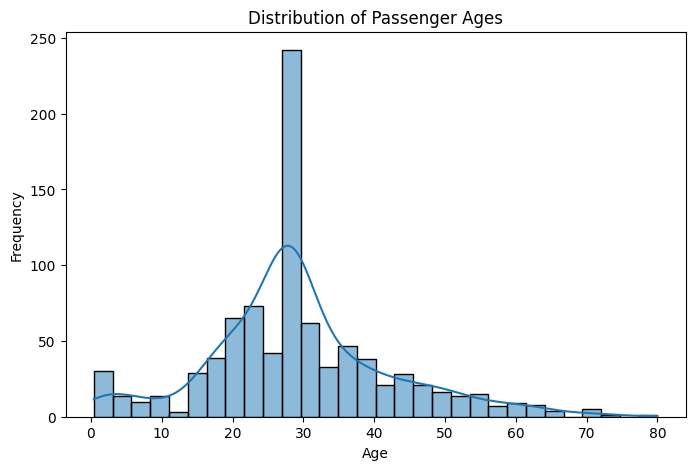

In [16]:
#visualise 
plt.figure(figsize=(8, 5))
sns.histplot(data= df, x="Age", bins=30, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

In [17]:
df.to_csv("Titanic-Cleaned.csv", index=False)